XGBOOST y SHAP

In [1]:
from sklearn.datasets import load_breast_cancer
data = load_breast_cancer()


In [2]:
from sklearn.datasets import load_breast_cancer
data = load_breast_cancer()
data.target[[10, 50, 85]]


array([0, 1, 0])

In [3]:
data.target_names[data.target[[10, 50, 85]]]   # 0 malign, 1 begning

array(['malignant', 'benign', 'malignant'], dtype='<U9')

In [4]:
from sklearn.model_selection import train_test_split
X, y = data.data, 1 - data.target #invierte
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=42)

In [5]:
#%pip install xgboost shap

In [6]:
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, recall_score, precision_score

xgb = XGBClassifier(n_estimators=200, max_depth=3, learning_rate=0.5, random_state=42)
xgb.fit(X_train, y_train)
pred = xgb.predict(X_test)
print("XGB")
print(f"Accuracy = {accuracy_score(y_test, pred):.3f} ")
print(f"Recall = {recall_score(y_test, pred):.3f} ")
print(f"Precision = {precision_score(y_test, pred):.3f} ")

XGB
Accuracy = 0.972 
Recall = 0.925 
Precision = 1.000 


In [7]:
import shap

# Calcula SHAP
explainer = shap.TreeExplainer(xgb)
sv = explainer(X_test)
sv.feature_names = list(data.feature_names)


Paciente 0 | clase real: benign


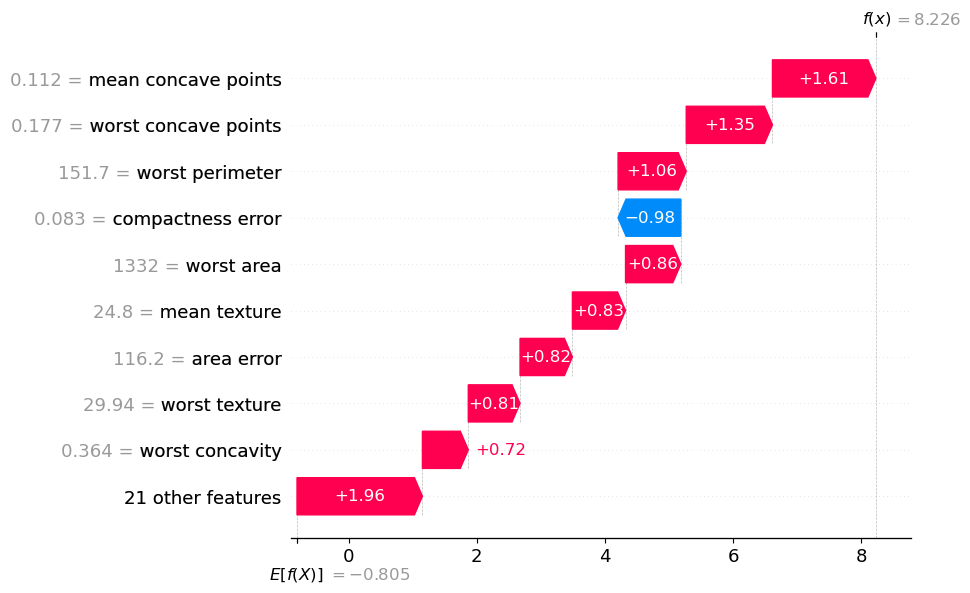

Paciente 1 | clase real: malignant


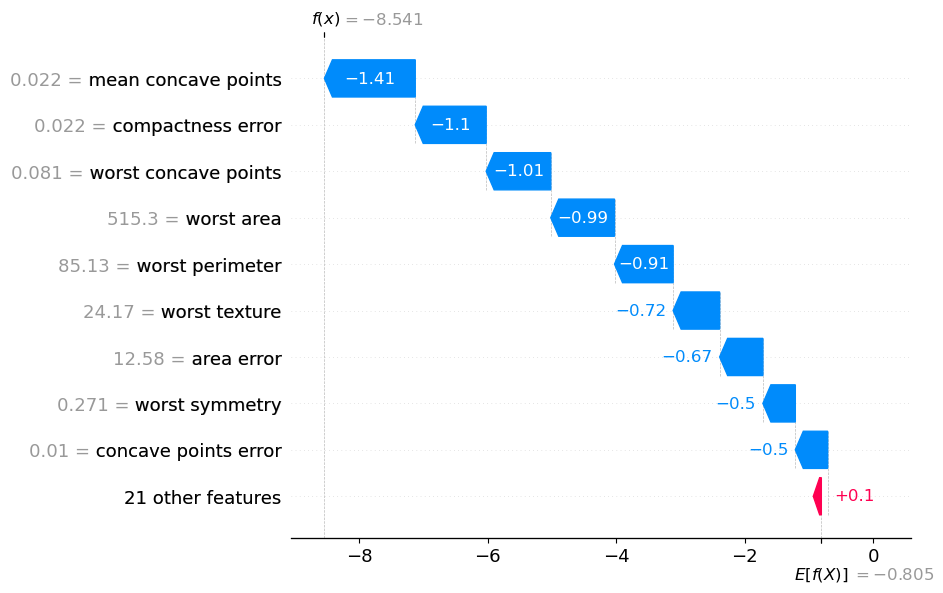

Paciente 2 | clase real: benign


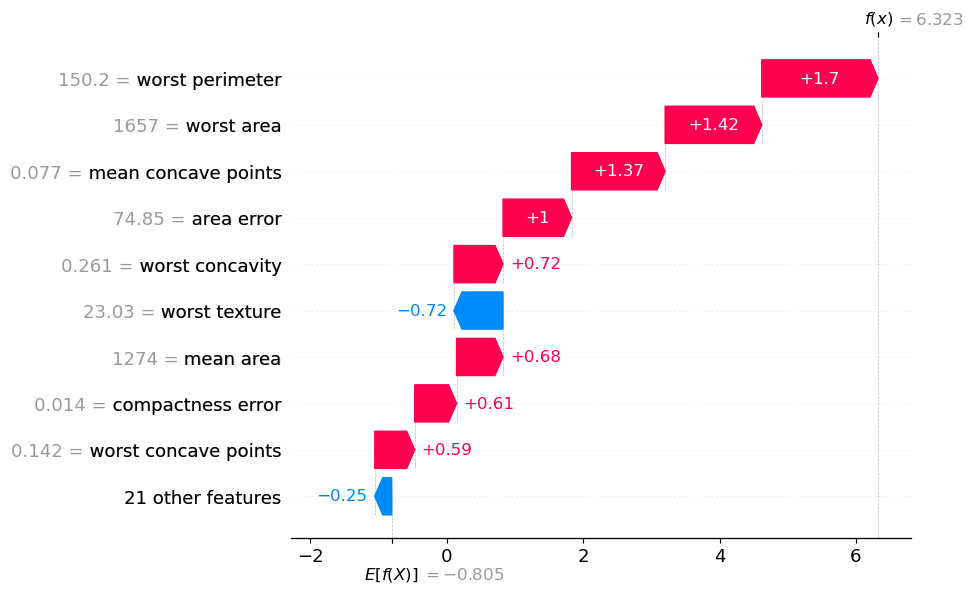

In [8]:
import numpy as np

pacientes = [0, 1, 2]
for i in pacientes:
    print(f"Paciente {i} | clase real: {data.target_names[np.asarray(y_test)[i]]}")
    shap.plots.waterfall(sv[i], max_display=10)

In [9]:
import numpy as np

margin = xgb.predict(X_test, output_margin=True)# log-odds para la suma
recon  = sv.base_values + sv.values.sum(axis=1)# φ₀ + Σφᵢ

for i in pacientes:
    print(f"Paciente {i}: φ₀={sv.base_values[i]:.4f}  Σφᵢ={sv.values[i].sum():.4f}  "
          f"suma={recon[i]:.4f}  log-odds={margin[i]:.4f}")

print("Coincide?", np.allclose(recon, margin, atol=1e-4))

Paciente 0: φ₀=-0.8051  Σφᵢ=9.0310  suma=8.2259  log-odds=8.2259
Paciente 1: φ₀=-0.8051  Σφᵢ=-7.7357  suma=-8.5408  log-odds=-8.5408
Paciente 2: φ₀=-0.8051  Σφᵢ=7.1279  suma=6.3228  log-odds=6.3228
Coincide? True


# Sanity check de SHAP pasado, a lo que sigue

In [10]:
import pandas as pd
from sklearn.inspection import permutation_importance

perm = permutation_importance(xgb, X_test, y_test, n_repeats=30, random_state=0, scoring="roc_auc")

comp = pd.DataFrame({
    "feature": data.feature_names,
    "shap_mean_abs": np.abs(sv.values).mean(axis=0),
    "perm_mean": perm.importances_mean,
})
comp["rank_shap"] = comp["shap_mean_abs"].rank(ascending=False).astype(int)
comp["rank_perm"] = comp["perm_mean"].rank(ascending=False).astype(int)
comp.sort_values("rank_shap").head(10)

,feature,shap_mean_abs,perm_mean,rank_shap,rank_perm
7,mean concave points,1.348101,0.002683,1,4
27,worst concave points,0.960770,0.007121,2,1
15,compactness error,0.925625,-0.000650,3,29
26,worst concavity,0.876576,0.004486,4,3
21,worst texture,0.846446,0.001635,5,7
22,worst perimeter,0.820547,0.000238,6,15
23,worst area,0.803354,0.004780,7,2
13,area error,0.740962,0.002145,8,6
1,mean texture,0.712388,0.000929,9,11
28,worst symmetry,0.576884,-0.000650,10,30


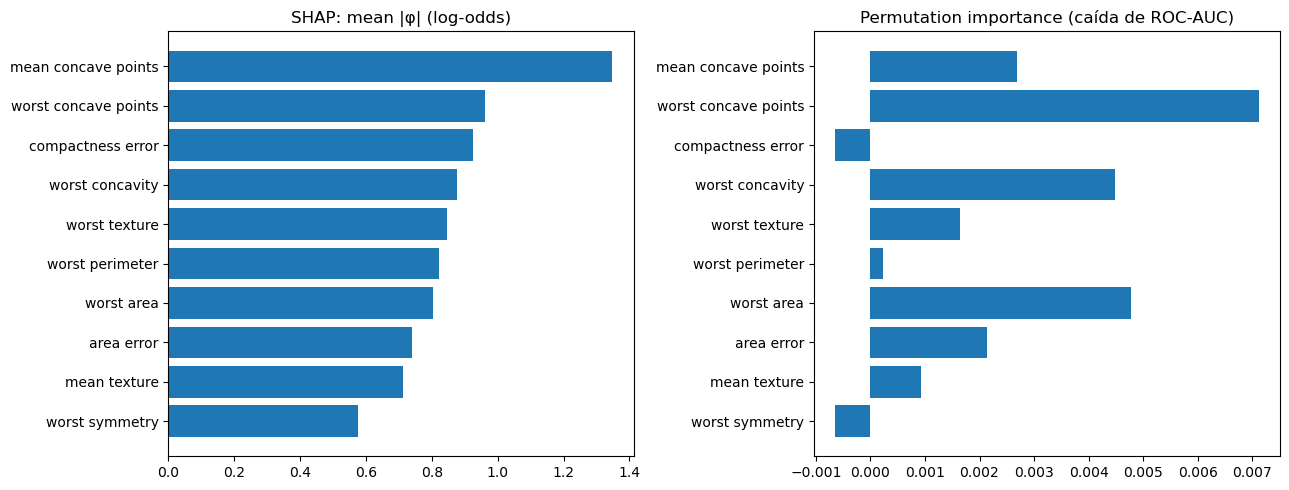

In [11]:
import matplotlib.pyplot as plt

top = comp.sort_values("shap_mean_abs", ascending=False).head(10)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].barh(top["feature"][::-1], top["shap_mean_abs"][::-1]); axes[0].set_title("SHAP: mean |φ| (log-odds)")
axes[1].barh(top["feature"][::-1], top["perm_mean"][::-1])
axes[1].set_title("Permutation importance (caída de ROC-AUC)")
plt.tight_layout();
plt.show()

**Interpretación:**
- SHAP mide cuanto empuja cada variable los log-odds en promedio. Si una variable cambia de log-odds SHAP registra un impacto alto.
- Permutation mide cuantas predicciones cambian de clase (y_test), es decir el accuracy, pero al no tomar en cuenta log-odds subestima la variable como con mean cave points, surgiendo problema de multicolinealidad.
- Variables como radious, perimeter y area estan fuertemente correlacionadas, SHAP reparte la atribucion entre todas las variables usadas en las ramas de los arboles
- Permutation en cambio muchas variables aparecen cercanas a cero porque el resto de variables correlacionadas compensan mantienen al paciente del mismo lado del umbral

In [12]:
# Parte 2 — Grad-CAM con ResNet-50

In [13]:
#%pip install torchvision
#%pip install --upgrade torch torchvision

In [17]:
import os, torch
from torchvision.models import resnet50, ResNet50_Weights

#Evita deadlock al correr todo el notebook
torch.set_num_threads(1)
weights = ResNet50_Weights.IMAGENET1K_V2
preprocess = weights.transforms()
categorias = weights.meta["categories"]

ruta = os.path.expanduser("~/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth")
sd = torch.load(ruta, map_location="cpu", weights_only=True)

model = resnet50(weights=None)
model.load_state_dict(sd)
model = model.eval()
print(sum(p.numel() for p in model.parameters()), "parámetros")

25557032 parámetros


In [15]:
import torch.nn.functional as F

class GradCAM:
    def __init__(self, model, layer):
        self.model = model
        self.acts = self.grads = None
        layer._forward_hooks.clear()
        layer._backward_hooks.clear()
        layer.register_forward_hook(lambda m, i, o: setattr(self, "acts", o))
        layer.register_full_backward_hook(lambda m, gi, go: setattr(self, "grads", go[0]))

    def __call__(self, x, class_idx):
        self.model.zero_grad()
        logits = self.model(x)
        logits[0, class_idx].backward()
        w = self.grads.mean(dim=(2, 3), keepdim=True)
        cam = F.relu((w * self.acts).sum(dim=1, keepdim=True))
        cam = F.interpolate(cam, size=x.shape[2:], mode="bilinear", align_corners=False)[0, 0]
        cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
        return cam.detach().numpy()

gradcam = GradCAM(model, model.layer4[-1])

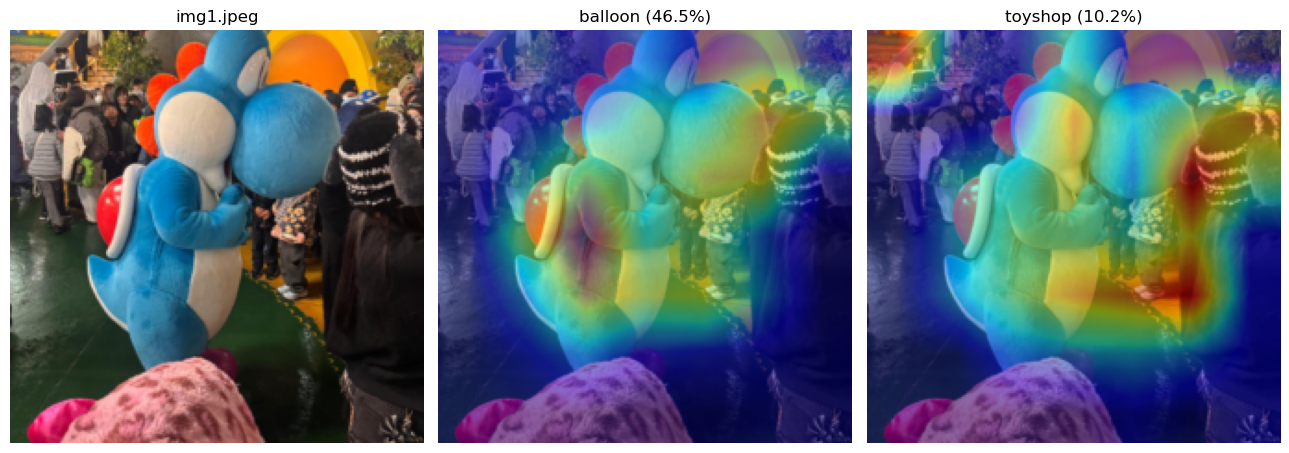

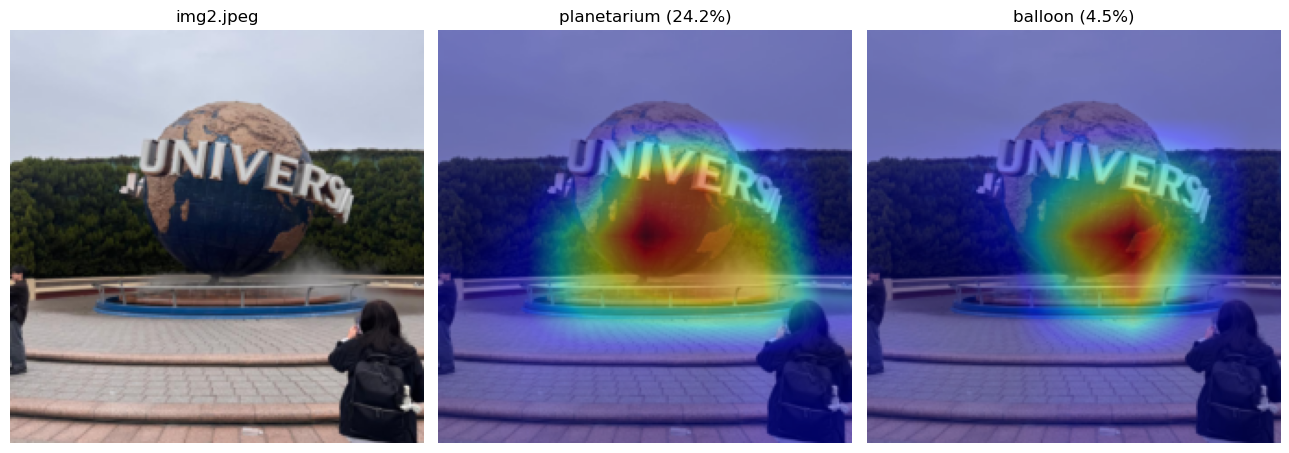

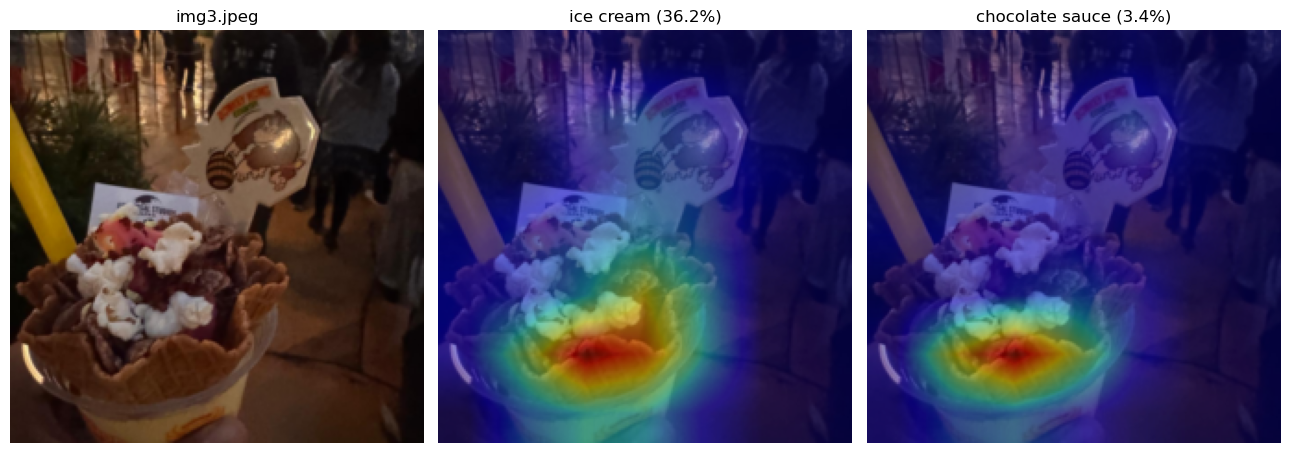

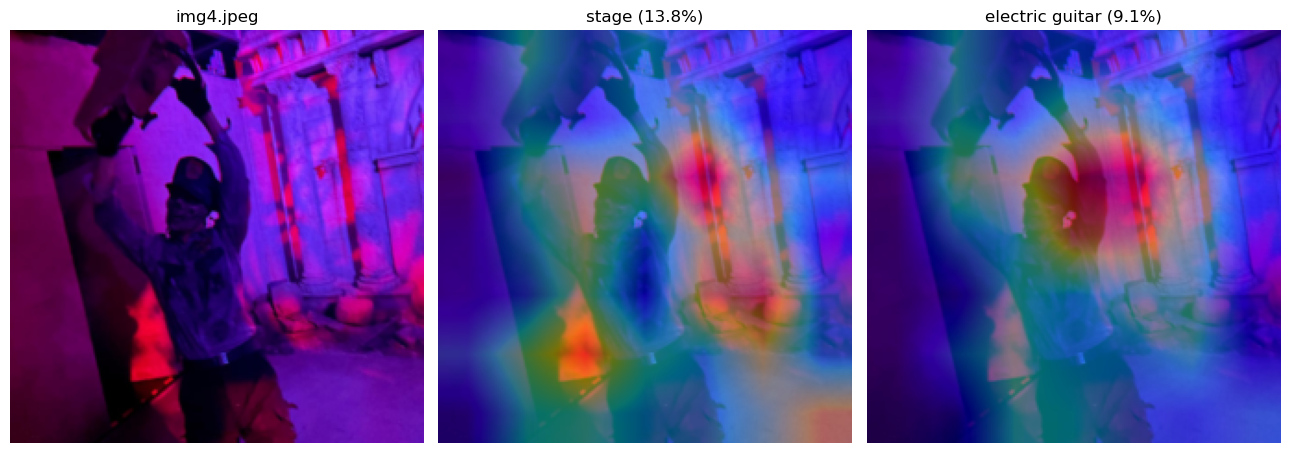

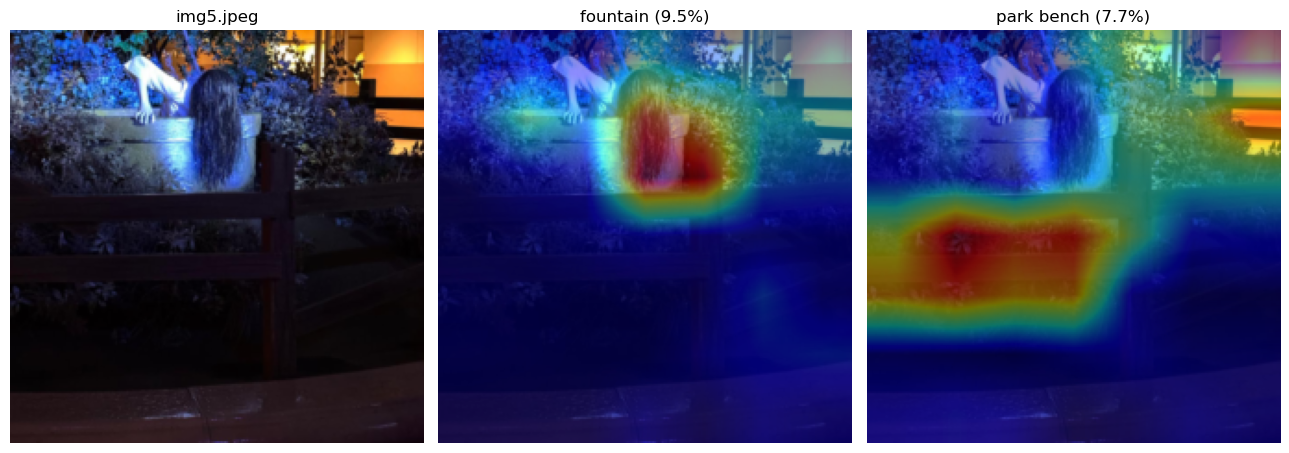

In [16]:
from PIL import Image
import matplotlib.pyplot as plt

imagenes = ["img1.jpeg", "img2.jpeg", "img3.jpeg", "img4.jpeg", "img5.jpeg"]

def desnormalizar(x):
    mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
    std  = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)
    return (x[0] * std + mean).clamp(0, 1).permute(1, 2, 0).numpy()

for ruta in imagenes:
    img = Image.open(ruta).convert("RGB")
    x = preprocess(img).unsqueeze(0)
    with torch.no_grad():
        probs = model(x).softmax(dim=1)[0]
    top2 = probs.topk(2)

    fig, axes = plt.subplots(1, 3, figsize=(13, 4.5))
    base = desnormalizar(x)
    axes[0].imshow(base); axes[0].set_title(ruta)
    for ax, p, c in zip(axes[1:], top2.values, top2.indices):
        cam = gradcam(x, c.item())
        ax.imshow(base); ax.imshow(cam, cmap="jet", alpha=0.45)
        ax.set_title(f"{categorias[c]} ({p:.1%})")
    for ax in axes: ax.axis("off")
    plt.tight_layout(); plt.show()

### Interpretación
1. Prediccion correcta sobre el helado o sundae (img3.jpeg)
2. Error de clasificacion en el resto sobretodo en la primera imagen al no contener categorias de personajes ficticios.
3. El mapa de calor muestra lo mas cercano a lo que contendria en sus categorias pero la primera imagen demuestra que falla completamente.